# Cleaning

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


In [3]:
df = pd.read_csv("../data/raw/retail_price.csv")

In [4]:
df.head(20)

,product_id,product_category_name,month_year,qty,total_price,freight_price,unit_price,product_name_lenght,product_description_lenght,product_photos_qty,...,comp_1,ps1,fp1,comp_2,ps2,fp2,comp_3,ps3,fp3,lag_price
0,bed1,bed_bath_table,01-05-2017,1,45.95,15.100000,45.950000,39,161,2,...,89.900000,3.9,15.011897,215.000000,4.4,8.760000,45.950000,4.0,15.100000,45.900000
1,bed1,bed_bath_table,01-06-2017,3,137.85,12.933333,45.950000,39,161,2,...,89.900000,3.9,14.769216,209.000000,4.4,21.322000,45.950000,4.0,12.933333,45.950000
2,bed1,bed_bath_table,01-07-2017,6,275.70,14.840000,45.950000,39,161,2,...,89.900000,3.9,13.993833,205.000000,4.4,22.195932,45.950000,4.0,14.840000,45.950000
3,bed1,bed_bath_table,01-08-2017,4,183.80,14.287500,45.950000,39,161,2,...,89.900000,3.9,14.656757,199.509804,4.4,19.412885,45.950000,4.0,14.287500,45.950000
4,bed1,bed_bath_table,01-09-2017,2,91.90,15.100000,45.950000,39,161,2,...,89.900000,3.9,18.776522,163.398710,4.4,24.324687,45.950000,4.0,15.100000,45.950000
5,bed1,bed_bath_table,01-10-2017,3,137.85,15.100000,45.950000,39,161,2,...,89.900000,3.9,21.572143,45.950000,4.0,15.100000,45.950000,4.0,15.100000,45.950000
6,bed1,bed_bath_table,01-11-2017,11,445.85,15.832727,40.531818,39,161,2,...,89.900000,3.9,16.294000,40.531818,4.0,15.832727,40.531818,4.0,15.832727,45.950000
7,bed1,bed_bath_table,01-12-2017,6,239.94,15.230000,39.990000,39,161,2,...,88.488235,3.9,18.898333,39.990000,4.0,15.230000,39.990000,4.0,15.230000,40.531818
8,bed1,bed_bath_table,01-01-2018,19,759.81,16.533684,39.990000,39,161,2,...,86.900000,3.9,19.383529,39.990000,4.0,16.533684,39.990000,4.0,16.533684,39.990000
9,bed1,bed_bath_table,01-02-2018,18,719.82,13.749444,39.990000,39,161,2,...,86.900000,3.9,19.209091,39.990000,4.0,13.749444,39.990000,4.0,13.749444,39.990000


In [5]:
# نشوف القيم الفريدة في كل عمود
print("Weekend values:", df['weekend'].unique())
print("Holiday values:", df['holiday'].unique())
print("Weekday values:", df['weekday'].unique())



Weekend values: [ 8 10  9]
Holiday values: [1 2 4 3 0]
Weekday values: [23 22 21 20]


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 676 entries, 0 to 675
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  676 non-null    object 
 1   product_category_name       676 non-null    object 
 2   month_year                  676 non-null    object 
 3   qty                         676 non-null    int64  
 4   total_price                 676 non-null    float64
 5   freight_price               676 non-null    float64
 6   unit_price                  676 non-null    float64
 7   product_name_lenght         676 non-null    int64  
 8   product_description_lenght  676 non-null    int64  
 9   product_photos_qty          676 non-null    int64  
 10  product_weight_g            676 non-null    int64  
 11  product_score               676 non-null    float64
 12  customers                   676 non-null    int64  
 13  weekday                     676 non

In [7]:
df.isnull().sum()

product_id                    0
product_category_name         0
month_year                    0
qty                           0
total_price                   0
freight_price                 0
unit_price                    0
product_name_lenght           0
product_description_lenght    0
product_photos_qty            0
product_weight_g              0
product_score                 0
customers                     0
weekday                       0
weekend                       0
holiday                       0
month                         0
year                          0
s                             0
volume                        0
comp_1                        0
ps1                           0
fp1                           0
comp_2                        0
ps2                           0
fp2                           0
comp_3                        0
ps3                           0
fp3                           0
lag_price                     0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.columns

Index(['product_id', 'product_category_name', 'month_year', 'qty',
       'total_price', 'freight_price', 'unit_price', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_score', 'customers', 'weekday', 'weekend', 'holiday', 'month',
       'year', 's', 'volume', 'comp_1', 'ps1', 'fp1', 'comp_2', 'ps2', 'fp2',
       'comp_3', 'ps3', 'fp3', 'lag_price'],
      dtype='object')

# EDA

<Axes: xlabel='unit_price', ylabel='Count'>

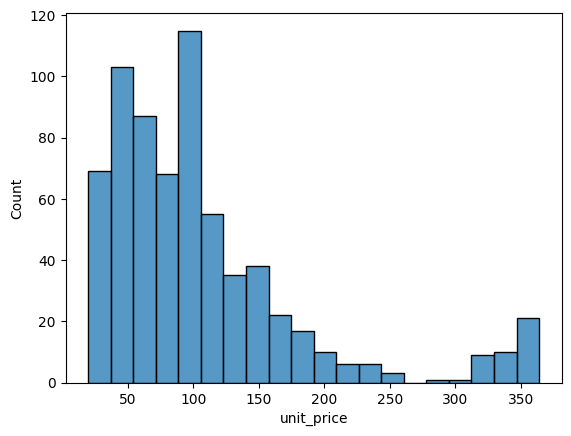

In [10]:
sns.histplot(df['unit_price'])

In [11]:
df['product_category_name'].value_counts()

product_category_name
garden_tools             160
health_beauty            130
watches_gifts            103
computers_accessories     69
bed_bath_table            61
cool_stuff                57
furniture_decor           48
perfumery                 26
consoles_games            22
Name: count, dtype: int64

<Axes: xlabel='count', ylabel='product_category_name'>

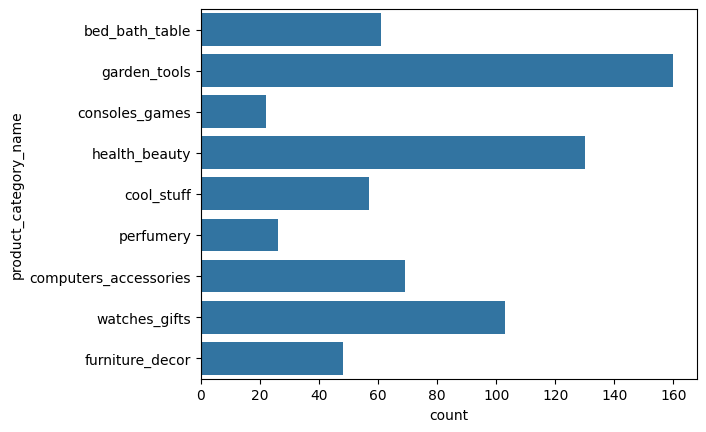

In [12]:
sns.countplot(df['product_category_name'])

<Axes: ylabel='unit_price'>

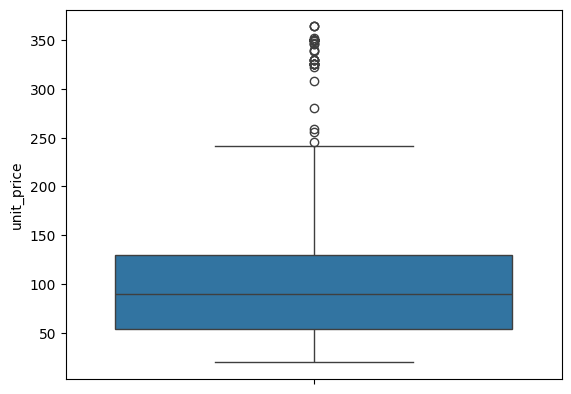

In [13]:
sns.boxplot(df['unit_price'])

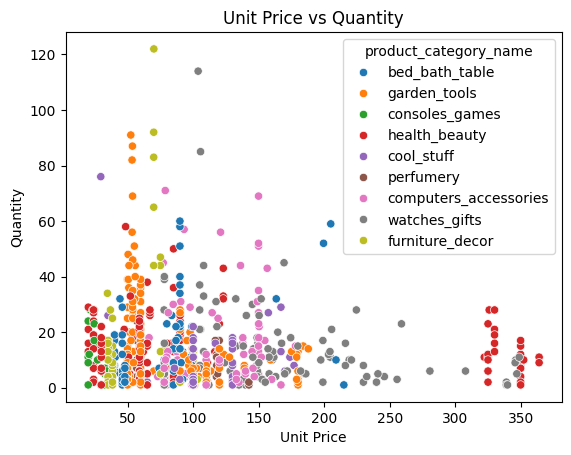

In [14]:
sns.scatterplot(x='unit_price',y='qty',hue='product_category_name',data=df)
plt.title('Unit Price vs Quantity')
plt.xlabel('Unit Price')
plt.ylabel('Quantity')
plt.show()

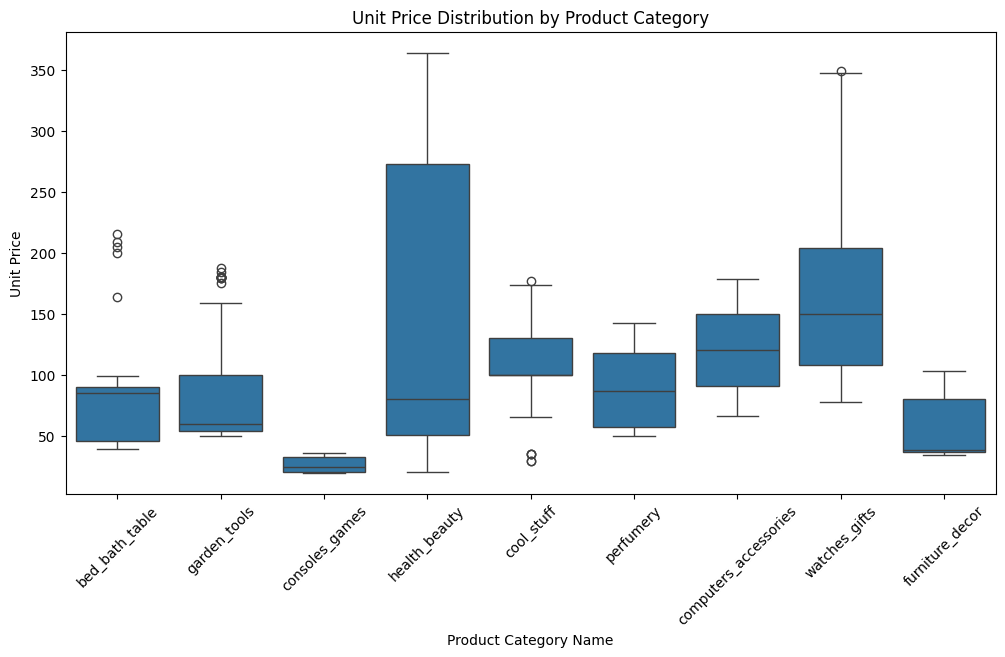

In [15]:
plt.figure(figsize=(12,6))
sns.boxplot(x='product_category_name',y='unit_price',data=df)
plt.xticks(rotation=45)
plt.title('Unit Price Distribution by Product Category')
plt.xlabel('Product Category Name')
plt.ylabel('Unit Price')
plt.show()

In [16]:
df['price_diff_1']=df['unit_price'] - df['comp_1']

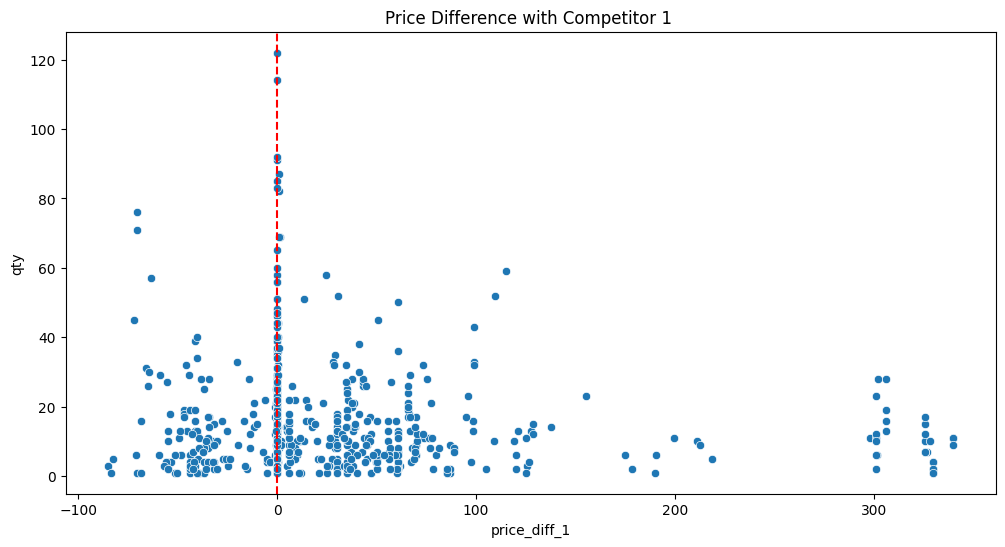

In [17]:
plt.figure(figsize=(12,6))
sns.scatterplot(x='price_diff_1',y='qty',data=df)
plt.axvline(0, color='red', linestyle='--')
plt.title('Price Difference with Competitor 1 ')
plt.show()

In [18]:
df['price_diff_2']=df['unit_price'] - df['comp_2']

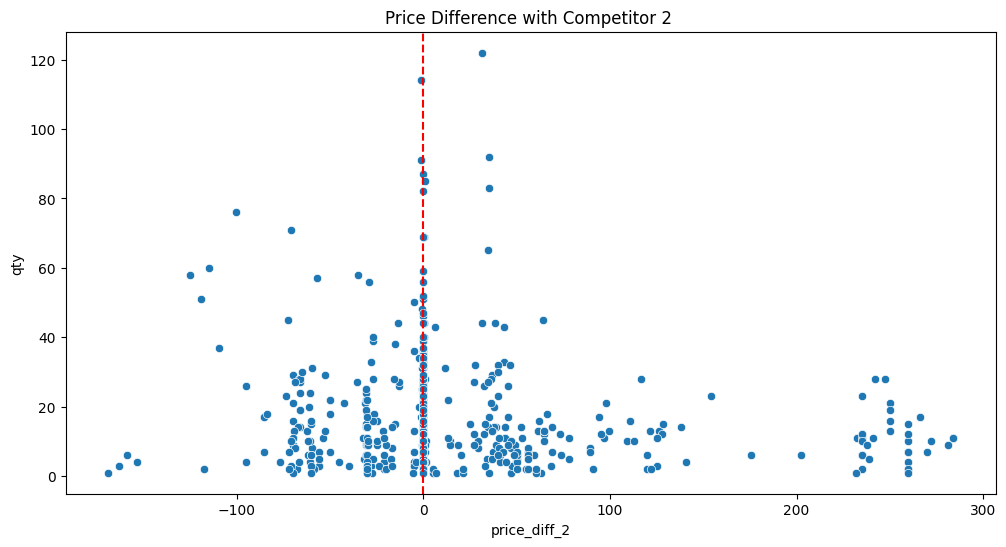

In [19]:
plt.figure(figsize=(12,6))
sns.scatterplot(x='price_diff_2',y='qty',data=df)
plt.axvline(0, color='red', linestyle='--')
plt.title('Price Difference with Competitor 2 ')
plt.show()

In [20]:
df['price_diff_3']=df['unit_price'] - df['comp_3']

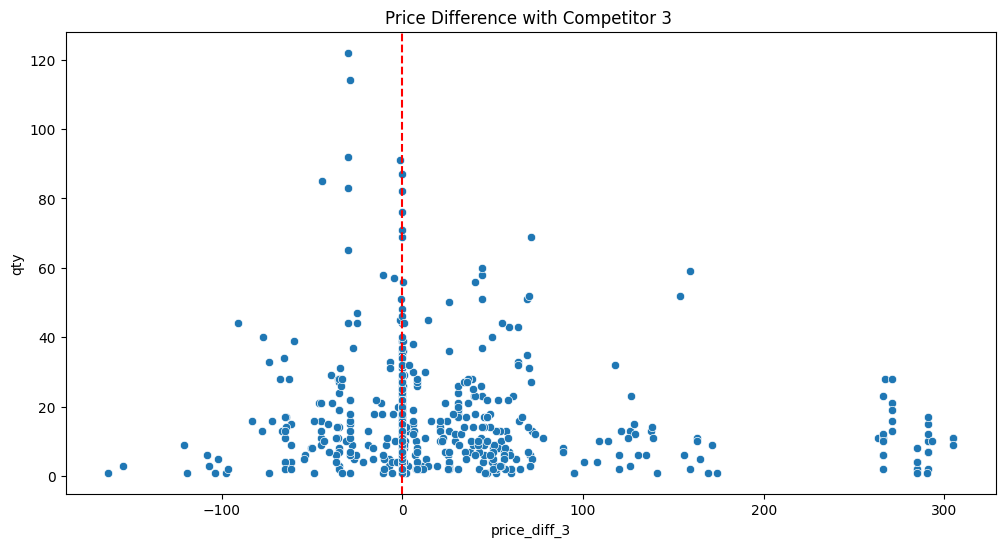

In [21]:
plt.figure(figsize=(12,6))
sns.scatterplot(x='price_diff_3',y='qty',data=df)
plt.axvline(0, color='red', linestyle='--')
plt.title('Price Difference with Competitor 3 ')
plt.show()

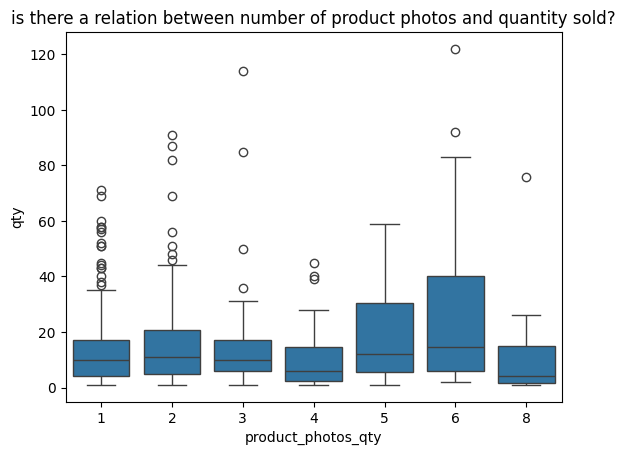

In [22]:
# علاقة عدد الصور بالمبيعات
sns.boxplot(x='product_photos_qty', y='qty', data=df)
plt.title("is there a relation between number of product photos and quantity sold?")
plt.show()

In [23]:
df['score_diff'] = df['product_score'] - df['ps1']

df.groupby(df['score_diff'] > 0)['qty'].mean()

score_diff
False    15.169661
True     12.565714
Name: qty, dtype: float64

In [24]:
df

,product_id,product_category_name,month_year,qty,total_price,freight_price,unit_price,product_name_lenght,product_description_lenght,product_photos_qty,...,ps2,fp2,comp_3,ps3,fp3,lag_price,price_diff_1,price_diff_2,price_diff_3,score_diff
0,bed1,bed_bath_table,01-05-2017,1,45.95,15.100000,45.950000,39,161,2,...,4.4,8.760000,45.95,4.0,15.100000,45.900000,-43.950000,-169.050000,0.000000,0.1
1,bed1,bed_bath_table,01-06-2017,3,137.85,12.933333,45.950000,39,161,2,...,4.4,21.322000,45.95,4.0,12.933333,45.950000,-43.950000,-163.050000,0.000000,0.1
2,bed1,bed_bath_table,01-07-2017,6,275.70,14.840000,45.950000,39,161,2,...,4.4,22.195932,45.95,4.0,14.840000,45.950000,-43.950000,-159.050000,0.000000,0.1
3,bed1,bed_bath_table,01-08-2017,4,183.80,14.287500,45.950000,39,161,2,...,4.4,19.412885,45.95,4.0,14.287500,45.950000,-43.950000,-153.559804,0.000000,0.1
4,bed1,bed_bath_table,01-09-2017,2,91.90,15.100000,45.950000,39,161,2,...,4.4,24.324687,45.95,4.0,15.100000,45.950000,-43.950000,-117.448710,0.000000,0.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
671,bed5,bed_bath_table,01-05-2017,1,215.00,8.760000,215.000000,56,162,5,...,4.4,8.760000,45.95,4.0,15.100000,214.950000,125.100000,0.000000,169.050000,0.5
672,bed5,bed_bath_table,01-06-2017,10,2090.00,21.322000,209.000000,56,162,5,...,4.4,21.322000,45.95,4.0,12.933333,215.000000,119.100000,0.000000,163.050000,0.5
673,bed5,bed_bath_table,01-07-2017,59,12095.00,22.195932,205.000000,56,162,5,...,4.4,22.195932,45.95,4.0,14.840000,209.000000,115.100000,0.000000,159.050000,0.5
674,bed5,bed_bath_table,01-08-2017,52,10375.00,19.412885,199.509804,56,162,5,...,4.4,19.412885,45.95,4.0,14.287500,205.000000,109.609804,0.000000,153.559804,0.5
